In [ ]:
!pip install prosail --quiet

In [ ]:
import numpy as np
import pandas as pd
import prosail
import matplotlib.pyplot as plt

np.random.seed(42)  # fixed seed = reproducible dataset;

In [ ]:
N_SAMPLES_PER_SPECIES = 20000   # target row count per species, per your spec
PROSAIL_WL_START = 400
PROSAIL_WL_END = 2500  # inclusive
PROSAIL_N_WL = PROSAIL_WL_END - PROSAIL_WL_START + 1  # 2101

In [ ]:
# (band_name, lower_wavelength_nm, upper_wavelength_nm, source)
ALL_BANDS = [
    # --- HLS / Landsat 8 OLI (L30 product) -- your primary satellite source ---
    ("HLS_Blue",   452, 512,  "HLS L30 / Landsat 8 OLI"),
    ("HLS_Green",  533, 590,  "HLS L30 / Landsat 8 OLI"),
    ("HLS_Red",    636, 673,  "HLS L30 / Landsat 8 OLI"),
    ("HLS_NIR",    851, 879,  "HLS L30 / Landsat 8 OLI"),
    ("HLS_SWIR1",  1566, 1651, "HLS L30 / Landsat 8 OLI"),
    ("HLS_SWIR2",  2107, 2294, "HLS L30 / Landsat 8 OLI"),

    # --- Sentinel-2 (HLS S30 product) -- includes the red-edge bands L30 lacks.
    #     Karthik confirmed HLS can pull these from the S30 half of HLS, or
    #     directly from Sentinel Hub. Full 13-band set included for completeness. ---
    ("S2_B1_CoastalAerosol", 433, 453,  "Sentinel-2 / HLS S30"),
    ("S2_B2_Blue",           458, 523,  "Sentinel-2 / HLS S30"),
    ("S2_B3_Green",          543, 578,  "Sentinel-2 / HLS S30"),
    ("S2_B4_Red",            650, 680,  "Sentinel-2 / HLS S30"),
    ("S2_B5_RedEdge1",       698, 713,  "Sentinel-2 / HLS S30"),
    ("S2_B6_RedEdge2",       733, 748,  "Sentinel-2 / HLS S30"),
    ("S2_B7_RedEdge3",       773, 793,  "Sentinel-2 / HLS S30"),
    ("S2_B8_NIR",            785, 900,  "Sentinel-2 / HLS S30"),
    ("S2_B8A_NIR_Narrow",    855, 875,  "Sentinel-2 / HLS S30"),
    ("S2_B9_WaterVapor",     935, 955,  "Sentinel-2 / HLS S30"),
    ("S2_B11_SWIR1",         1565, 1655, "Sentinel-2 / HLS S30"),
    ("S2_B12_SWIR2",         2100, 2280, "Sentinel-2 / HLS S30"),


    ("WG_Blue",    435, 465,  "WeedsGalore / DJI P4 Multispectral (approx. +/-15nm)"),
    ("WG_Green",   545, 575,  "WeedsGalore / DJI P4 Multispectral (approx. +/-15nm)"),
    ("WG_Red",     635, 665,  "WeedsGalore / DJI P4 Multispectral (approx. +/-15nm)"),
    ("WG_RedEdge", 715, 745,  "WeedsGalore / DJI P4 Multispectral (approx. +/-15nm)"),
    ("WG_NIR",     825, 855,  "WeedsGalore / DJI P4 Multispectral (approx. +/-15nm)"),
]

def band_average(spectrum, lo_nm, hi_nm):
    """Average the portion of a 400-2500nm PROSAIL spectrum between lo_nm and hi_nm."""
    lo_idx = lo_nm - PROSAIL_WL_START
    hi_idx = hi_nm - PROSAIL_WL_START
    return float(np.mean(spectrum[lo_idx:hi_idx + 1]))


GROWTH_STAGES = ["early", "mid_rising", "peak", "late_plateau"]

def stage_lai_range(lai_min, lai_max, stage):
    """Split the real overall LAI range into 4 growth-stage sub-ranges."""
    span = lai_max - lai_min
    # early: bottom 25% of range; mid_rising: 25-65%; peak: 55-100%; late: 70-100% (slight pullback from peak)
    windows = {
        "early":        (lai_min, lai_min + 0.30 * span),
        "mid_rising":   (lai_min + 0.25 * span, lai_min + 0.70 * span),
        "peak":         (lai_min + 0.60 * span, lai_max),
        "late_plateau": (lai_min + 0.45 * span, lai_max),
    }
    return windows[stage]

In [ ]:
cotton_params = pd.read_excel("Cotton_PROSAIL_Parameters.xlsx", header=3)
palmer_params = pd.read_excel("Palmer_Amaranth_PROSAIL_Parameters.xlsx", header=3)


cotton_params = cotton_params.dropna(subset=["Min Value"]).reset_index(drop=True)
palmer_params = palmer_params.dropna(subset=["Min Value"]).reset_index(drop=True)

def params_to_dict(df):
    """Turn a parameter table into {code: (min, max)} for easy lookup."""
    return {row["PROSPECT/SAIL Code"]: (row["Min Value"], row["Max Value"]) for _, row in df.iterrows()}

cotton_ranges = params_to_dict(cotton_params)
palmer_ranges = params_to_dict(palmer_params)

print("Cotton parameter ranges loaded:")
for k, v in cotton_ranges.items():
    print(f"  {k}: {v[0]} to {v[1]}")
print("\nPalmer amaranth parameter ranges loaded:")
for k, v in palmer_ranges.items():
    print(f"  {k}: {v[0]} to {v[1]}")

Cotton parameter ranges loaded:
  cab: 32.3 to 63.6
  car: 1.0 to 9.3
  cw: 0.015 to 0.015
  cm: 0.0036 to 0.0105
  n: 1.0 to 2.5
  lai: 0.5 to 4.5
  lidfa: 57.3 to 57.3
  hspot: 0.01 to 0.05
  psoil: 0.0 to 1.0
  tts: 20.0 to 50.0
  tto: 0.0 to 10.0
  psi: 0.0 to 180.0

Palmer amaranth parameter ranges loaded:
  cab: 22.8 to 31.7
  car: 8.0 to 8.0
  cw: 0.015 to 0.015
  cm: 0.0036 to 0.0105
  n: 1.0 to 2.5
  lai: 0.4 to 1.2
  lidfa: 6.0 to 30.0
  hspot: 0.01 to 0.05
  psoil: 0.0 to 1.0
  tts: 20.0 to 50.0
  tto: 0.0 to 10.0
  psi: 0.0 to 180.0


In [ ]:
def sample_one_plant(ranges):
    """
    Draw one random, physically plausible virtual plant.
    ranges: dict of {code: (min, max)} for this species.
    Returns: dict of sampled parameter values, plus the growth stage label.
    """
    stage = np.random.choice(GROWTH_STAGES)

    # LAI gets the growth-stage treatment; everything else is a plain uniform
    # draw across its full real (or fixed-default) range.
    lai_min, lai_max = ranges["lai"]
    stage_lo, stage_hi = stage_lai_range(lai_min, lai_max, stage)
    lai_val = np.random.uniform(stage_lo, stage_hi)

    def draw(code):
        lo, hi = ranges[code]
        if lo == hi:  # fixed-by-convention parameter -> constant, not sampled
            return lo
        return np.random.uniform(lo, hi)

    plant = {
        "n": draw("n"),
        "cab": draw("cab"),
        "car": draw("car"),
        "cbrown": 0.0,          # healthy green leaf assumption; not in parameter tables
        "cw": draw("cw"),
        "cm": draw("cm"),
        "lai": lai_val,
        "lidfa": draw("lidfa"),
        "hspot": draw("hspot"),
        "tts": draw("tts"),
        "tto": draw("tto"),
        "psi": draw("psi"),
        "psoil": draw("psoil"),
        "growth_stage": stage,
    }
    return plant

In [ ]:
def generate_dataset(ranges, species_label, n_samples):
    """
    Generate n_samples rows for one species.
    Returns two things:
      - a DataFrame with input parameters + every named band (for direct use)
      - a numpy array of shape (n_samples, 2101) holding the FULL raw PROSAIL
        spectrum for every plant, at 1nm resolution from 400-2500nm, so
        nothing PROSAIL computes is ever discarded.
    """
    rows = []
    full_spectra = np.zeros((n_samples, PROSAIL_N_WL), dtype=np.float32)

    for i in range(n_samples):
        plant = sample_one_plant(ranges)

        spectrum = prosail.run_prosail(
            n=plant["n"], cab=plant["cab"], car=plant["car"], cbrown=plant["cbrown"],
            cw=plant["cw"], cm=plant["cm"], lai=plant["lai"], lidfa=plant["lidfa"],
            hspot=plant["hspot"], tts=plant["tts"], tto=plant["tto"], psi=plant["psi"],
            rsoil=1.0, psoil=plant["psoil"], typelidf=2, prospect_version="D",
        )
        full_spectra[i, :] = spectrum

        row = dict(plant)
        row["species"] = species_label
        for band_name, lo_nm, hi_nm, _source in ALL_BANDS:
            row[band_name] = band_average(spectrum, lo_nm, hi_nm)
        rows.append(row)

        if (i + 1) % 2000 == 0:
            print(f"  {species_label}: {i + 1}/{n_samples} done")

    return pd.DataFrame(rows), full_spectra

In [ ]:
print("Generating cotton dataset...")
cotton_df, cotton_full_spectra = generate_dataset(cotton_ranges, "cotton", N_SAMPLES_PER_SPECIES)

print("\nGenerating Palmer amaranth dataset...")
palmer_df, palmer_full_spectra = generate_dataset(palmer_ranges, "palmer_amaranth", N_SAMPLES_PER_SPECIES)

Generating cotton dataset...
  cotton: 2000/20000 done
  cotton: 4000/20000 done
  cotton: 6000/20000 done
  cotton: 8000/20000 done
  cotton: 10000/20000 done
  cotton: 12000/20000 done
  cotton: 14000/20000 done
  cotton: 16000/20000 done
  cotton: 18000/20000 done
  cotton: 20000/20000 done

Generating Palmer amaranth dataset...
  palmer_amaranth: 2000/20000 done
  palmer_amaranth: 4000/20000 done
  palmer_amaranth: 6000/20000 done
  palmer_amaranth: 8000/20000 done
  palmer_amaranth: 10000/20000 done
  palmer_amaranth: 12000/20000 done
  palmer_amaranth: 14000/20000 done
  palmer_amaranth: 16000/20000 done
  palmer_amaranth: 18000/20000 done
  palmer_amaranth: 20000/20000 done


In [ ]:
cotton_df.to_csv("cotton_prosail_synthetic.csv", index=False)
palmer_df.to_csv("palmer_amaranth_prosail_synthetic.csv", index=False)
np.save("cotton_full_spectra_400_2500nm.npy", cotton_full_spectra)
np.save("palmer_amaranth_full_spectra_400_2500nm.npy", palmer_full_spectra)

# A small text file recording exactly what column (wavelength) is where in the .npy files.
wavelengths = np.arange(PROSAIL_WL_START, PROSAIL_WL_END + 1)
np.savetxt("full_spectrum_wavelengths_nm.csv", wavelengths, fmt="%d", header="wavelength_nm", comments="")

print(f"\nSaved cotton_prosail_synthetic.csv: {cotton_df.shape[0]} rows, {cotton_df.shape[1]} columns")
print(f"Saved palmer_amaranth_prosail_synthetic.csv: {palmer_df.shape[0]} rows, {palmer_df.shape[1]} columns")
print(f"Saved full-resolution spectra: {cotton_full_spectra.shape} and {palmer_full_spectra.shape} (rows x wavelengths, 400-2500nm @ 1nm)")
print("Saved full_spectrum_wavelengths_nm.csv -- maps each .npy column to its wavelength in nm")


Saved cotton_prosail_synthetic.csv: 20000 rows, 38 columns
Saved palmer_amaranth_prosail_synthetic.csv: 20000 rows, 38 columns
Saved full-resolution spectra: (20000, 2101) and (20000, 2101) (rows x wavelengths, 400-2500nm @ 1nm)
Saved full_spectrum_wavelengths_nm.csv -- maps each .npy column to its wavelength in nm


In [ ]:
print("\n--- Sanity check: NIR/Red ratio (should be well above 1 for healthy vegetation) ---")
print("Cotton mean NIR/Red ratio (HLS bands):", (cotton_df["HLS_NIR"] / cotton_df["HLS_Red"]).mean().round(3))
print("Palmer amaranth mean NIR/Red ratio (HLS bands):", (palmer_df["HLS_NIR"] / palmer_df["HLS_Red"]).mean().round(3))
print("Cotton mean NIR/Red ratio (WeedsGalore-matching bands):", (cotton_df["WG_NIR"] / cotton_df["WG_Red"]).mean().round(3))
print("Palmer amaranth mean NIR/Red ratio (WeedsGalore-matching bands):", (palmer_df["WG_NIR"] / palmer_df["WG_Red"]).mean().round(3))


--- Sanity check: NIR/Red ratio (should be well above 1 for healthy vegetation) ---
Cotton mean NIR/Red ratio (HLS bands): 16.645
Palmer amaranth mean NIR/Red ratio (HLS bands): 5.769
Cotton mean NIR/Red ratio (WeedsGalore-matching bands): 15.975
Palmer amaranth mean NIR/Red ratio (WeedsGalore-matching bands): 5.484


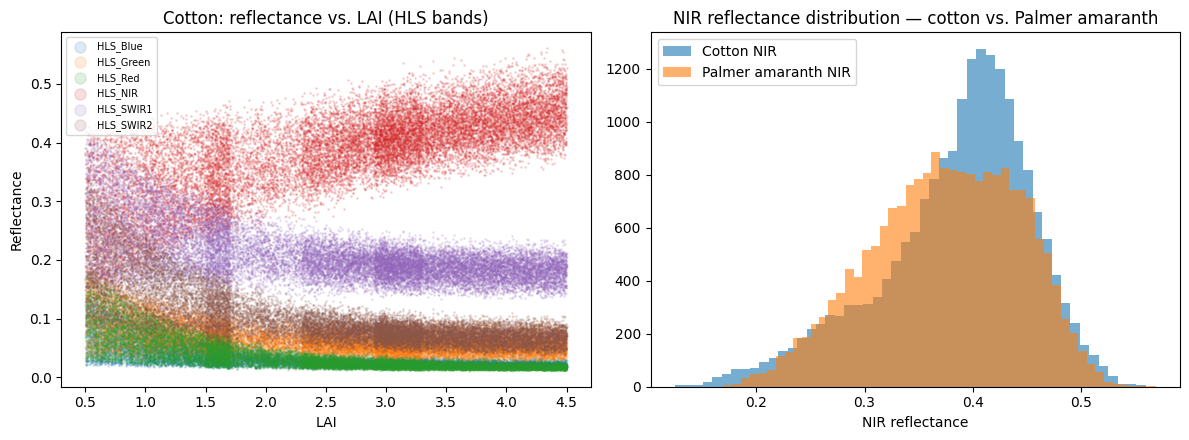


Done. Files ready: cotton_prosail_synthetic.csv, palmer_amaranth_prosail_synthetic.csv, prosail_sanity_check_plots.png


In [ ]:
HLS_PLOT_BANDS = ["HLS_Blue", "HLS_Green", "HLS_Red", "HLS_NIR", "HLS_SWIR1", "HLS_SWIR2"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for band_name in HLS_PLOT_BANDS:
    axes[0].scatter(cotton_df["lai"], cotton_df[band_name], s=1, alpha=0.15, label=band_name)
axes[0].set_title("Cotton: reflectance vs. LAI (HLS bands)")
axes[0].set_xlabel("LAI")
axes[0].set_ylabel("Reflectance")
axes[0].legend(markerscale=8, fontsize=7)

axes[1].hist(cotton_df["HLS_NIR"], bins=50, alpha=0.6, label="Cotton NIR")
axes[1].hist(palmer_df["HLS_NIR"], bins=50, alpha=0.6, label="Palmer amaranth NIR")
axes[1].set_title("NIR reflectance distribution — cotton vs. Palmer amaranth")
axes[1].set_xlabel("NIR reflectance")
axes[1].legend()

plt.tight_layout()
plt.savefig("prosail_sanity_check_plots.png", dpi=120)
plt.show()

print("\nDone. Files ready: cotton_prosail_synthetic.csv, palmer_amaranth_prosail_synthetic.csv, prosail_sanity_check_plots.png")